# Clustering Alamat Antar Jemput Sekolah
**Tujuan:** mengelompokkan alamat siswa sehingga satu cluster = satu kendaraan (maks. 10 siswa) dan alamat yang berdekatan berada dalam kendaraan yang sama.
Urutan jemput dan jarak tempuh tidak dihitung karena kondisi jalan sangat bervariasi.

**Workflow:**
1. Membaca & membersihkan data
2. Mengisi koordinat sekolah
3. Mengubah koordinat derajat menjadi kilometer
4. Menentukan jumlah kendaraan
5. Clustering berkapasitas (Capacitated K-Means & Sweep) + local search
6. Validasi, visualisasi & ekspor

> Pastikan file `clustering_core.py` berada di folder yang sama dengan notebook ini.

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import clustering_core as cc

FILE_DATA = "DataSetAlamat_clean.xlsx"   # ganti sesuai nama file Anda
SEKOLAH = (-1.634472, 103.492810)        # (latitude, longitude) sekolah — salin dari Google Maps
KAPASITAS = 10                           # maksimal siswa per kendaraan

## 1. Membaca & membersihkan data

In [2]:
df, peta_kolom, peringatan = cc.siapkan_data(pd.read_excel(FILE_DATA))
print("Pemetaan kolom:", peta_kolom)
print("Peringatan:", peringatan or "-")
print("Jumlah siswa:", len(df))
df.head(10)

Pemetaan kolom: {'alamat': 'alamat', 'lat': 'x', 'lon': 'y'}
Peringatan: -
Jumlah siswa: 83


,id_siswa,alamat,lat,lon
0,1,Permata simpang rimbo,-1.624532,103.546493
1,2,Argentina,-1.637844,103.586634
2,3,Argentina,-1.637844,103.586634
3,4,Lorong siolo,-1.647504,103.600462
4,5,SMK Taruna,-1.649012,103.602390
5,6,Jln. Sunan gunung Jati,-1.650132,103.592379
6,7,Perum Teras Marlini,-1.650890,103.588881
7,8,Jln. Sunan gunung Jati,-1.650132,103.592379
8,9,Perumahan Garden Village,-1.659829,103.595475
9,10,Talang gulo,-1.681219,103.617206


In [3]:
# Alamat dengan lebih dari satu siswa (mis. kakak-adik) — akan selalu satu kendaraan
jml = df.groupby(["alamat", "lat", "lon"]).size().sort_values(ascending=False)
print("Titik jemput unik:", len(jml))
jml[jml > 1]

Titik jemput unik: 58


alamat                        lat        lon       
Terrace Hill                  -1.636635  103.508520    5
SMA Titian Teras              -1.597331  103.465219    4
Sevilla                       -1.638329  103.570800    4
Perumahan Arza Griya Mandiri  -1.605708  103.527077    3
Aston Villa                   -1.616608  103.532278    3
Jln. Sunan gunung Jati        -1.650132  103.592379    2
Bukit Cempaka                 -1.637744  103.489083    2
Citraland                     -1.649954  103.579371    2
Garuda                        -1.652709  103.554959    2
Argentina                     -1.637844  103.586634    2
Pematang Gajah                -1.634833  103.518296    2
Pematang Sulur                -1.609753  103.578171    2
Paal 11                       -1.675036  103.590797    2
Puri Mayang                   -1.634541  103.580332    2
New Castle                    -1.639636  103.595873    2
Masjid Addin                  -1.618687  103.528603    2
dtype: int64

## 2. Koordinat sekolah
Dipakai sebagai acuan arah pada metode Sweep dan untuk penomoran kendaraan (searah jarum jam dari utara).
Cara mendapatkannya: Google Maps → klik kanan lokasi sekolah → klik angka koordinat (tersalin otomatis).

In [4]:
sekolah = SEKOLAH
# atau dari teks salinan Google Maps:
# sekolah = cc.parse_koordinat("-1.634472, 103.492810")
print(f"Lokasi sekolah: lat={sekolah[0]:.6f}, lon={sekolah[1]:.6f}")
print("Peringatan:", cc.validasi_sekolah(sekolah, df) or "-")

Lokasi sekolah: lat=-1.634472, lon=103.492810
Peringatan: -


## 3. Konversi derajat → kilometer
Satu derajat lintang ≈ 111 km, satu derajat bujur ≈ 111 km × cos(lintang). Koordinat diproyeksikan ke bidang datar (km) dengan sekolah di titik (0, 0) agar ukuran 'berdekatan' adil ke segala arah.

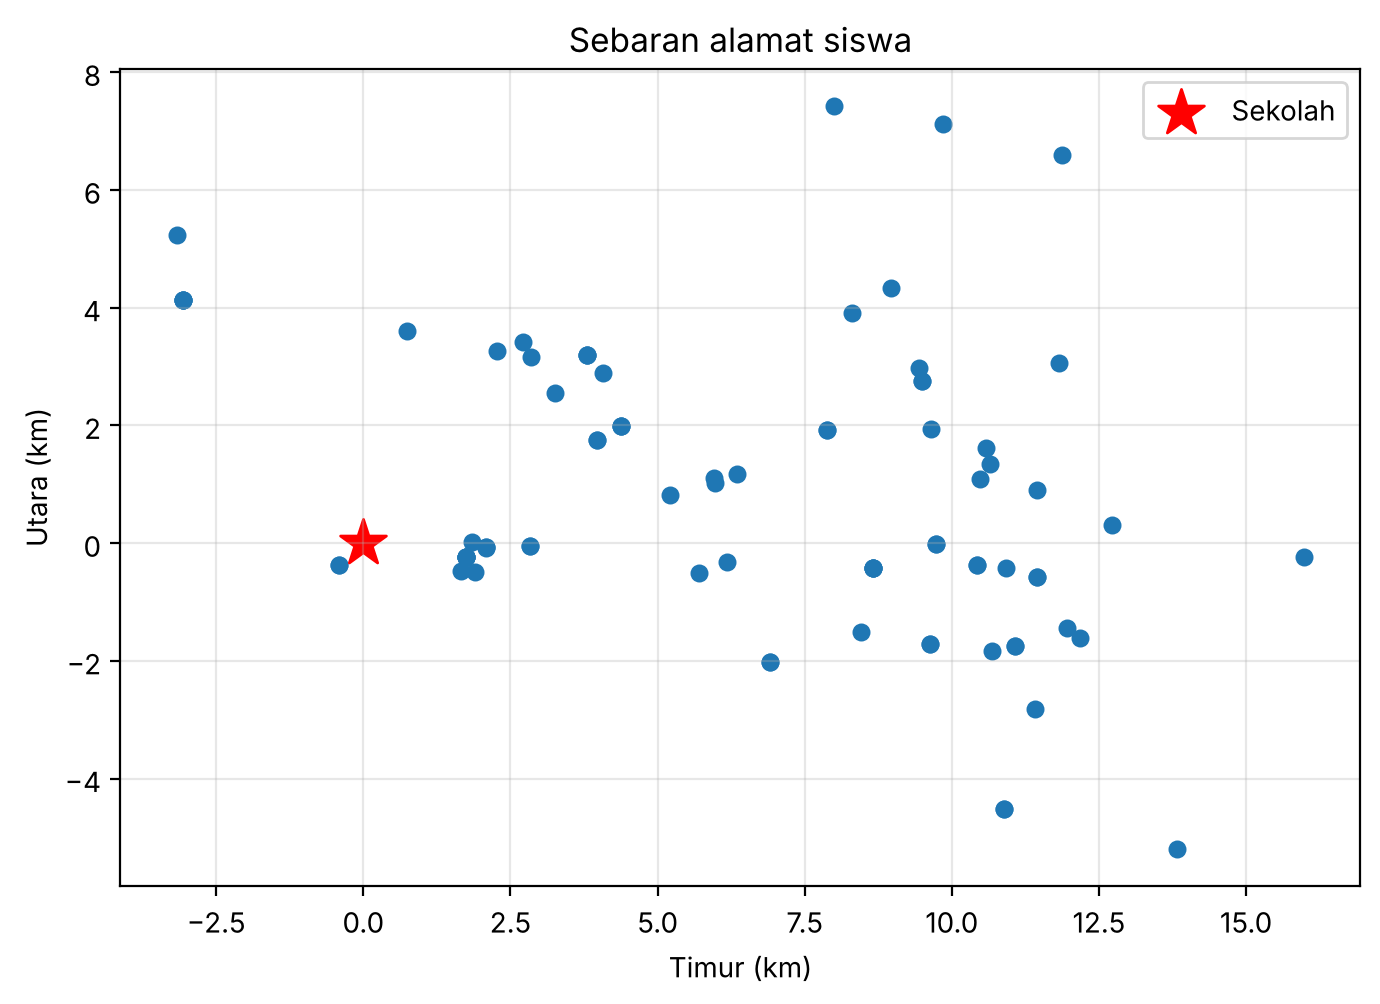

In [5]:
xy = cc.ke_km_lokal(df.lat.values, df.lon.values, *sekolah)
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(xy[:, 0], xy[:, 1], s=30)
ax.scatter([0], [0], marker="*", s=300, c="red", label="Sekolah")
ax.set_xlabel("Timur (km)"); ax.set_ylabel("Utara (km)"); ax.set_aspect("equal")
ax.set_title("Sebaran alamat siswa"); ax.legend(); ax.grid(alpha=.3)
plt.show()

## 4. Jumlah kendaraan
Jumlah kendaraan minimum = ⌈jumlah siswa / kapasitas⌉.

In [6]:
k_min = math.ceil(len(df) / KAPASITAS)
print(f"{len(df)} siswa / {KAPASITAS} kursi = minimal {k_min} kendaraan")

83 siswa / 10 kursi = minimal 9 kendaraan


## 5. Clustering berkapasitas
- **Capacitated K-Means**: pusat awal dari K-Means, lalu penugasan siswa memakai algoritma Hungarian (`linear_sum_assignment`) dengan `KAPASITAS` kursi per kendaraan → batas kapasitas dijamin. Diulang dengan beberapa random seed.
- **Sweep**: alamat diurutkan menurut sudut terhadap sekolah lalu diisi berurutan sampai penuh.
- **Local search**: pindah/tukar alamat antar-kendaraan untuk memperkecil SSE (jumlah jarak kuadrat ke pusat cluster).
- **Mode `auto`**: memilih hasil dengan SSE terkecil (paling kompak).

In [7]:
hasil = cc.jalankan_clustering(df, sekolah, kapasitas=KAPASITAS, metode="auto", n_percobaan=10)
print("\n".join(hasil.log))

Jumlah siswa: 83 | kapasitas: 10 | jumlah kendaraan: 9
Jumlah titik jemput unik: 56
Capacitated K-Means: SSE terbaik = 183.29
Sweep: SSE terbaik = 205.50
Dipilih: Capacitated K-Means (SSE 183.29; semakin kecil semakin kompak)


In [8]:
pd.set_option("display.max_colwidth", 200)
hasil.ringkasan

,kendaraan,jumlah_siswa,jumlah_titik_jemput,pusat_lat,pusat_lon,daftar_alamat
0,1,9,7,-1.606015,103.520138,"Cucian Motor berkah, Jalan ness, Kemajuan, Perumahan Arza Griya Mandiri, Perumahan Mendalo Mas, Perumahan Ridena, Perumahan Valencia"
1,2,10,9,-1.595911,103.579984,"Buluran, Jalan Lintas Timur Nomor 21, Jalan Nurijah Arifin Manaf Sebrang, Lazio, Nusa Indah, Pematang Sulur, Sebrang, Sipin, Telanai Indah"
2,3,10,5,-1.626233,103.522538,"Aston Villa, Masjid Addin, Pematang Gajah, Royal Palm, Royal palm"
3,4,10,8,-1.631693,103.551250,"Garuda, Jl. Pattimura, Kapten Pattimura, Kota Baru Indah, Mendalo Park, Penerangan, Permata simpang rimbo, Perumahan Bougenville, Perumahan Permata Citra"
4,5,10,8,-1.631823,103.592292,"Argentina, Belakang PU, Grand Purnama, JBC, Jl. Sunan Giri, Lorong Rina, New Castle, SIT Al Mutmainnah"
5,6,9,4,-1.641151,103.574607,"Citraland, Puri Mayang, Sevilla, Sunderland"
6,7,10,8,-1.657534,103.600740,"Jln. Sunan gunung Jati, Lorong siolo, Paal 11, Paal Merah Baru, Perum Teras Marlini, Perumahan Garden Village, SMK Taruna, Talang gulo"
7,8,10,5,-1.637069,103.504785,"Bukit Cempaka, Park Avenue, Spring Hill, Terrace Hill"
8,9,5,2,-1.595356,103.465036,"Pijoan, SMA Titian Teras"


In [9]:
hasil.detail

,kendaraan,id_siswa,alamat,lat,lon
0,1,27,Cucian Motor berkah,-1.605163,103.513248
1,1,26,Jalan ness,-1.602013,103.499440
2,1,77,Kemajuan,-1.611577,103.522158
3,1,79,Perumahan Arza Griya Mandiri,-1.605708,103.527077
4,1,80,Perumahan Arza Griya Mandiri,-1.605708,103.527077
...,...,...,...,...,...
78,9,32,Pijoan,-1.587455,103.464304
79,9,28,SMA Titian Teras,-1.597331,103.465219
80,9,29,SMA Titian Teras,-1.597331,103.465219
81,9,30,SMA Titian Teras,-1.597331,103.465219


## 6. Validasi

In [10]:
muatan = hasil.detail.groupby("kendaraan").size()
print("Muatan per kendaraan:", muatan.to_dict())
assert muatan.max() <= KAPASITAS, "Ada kendaraan melebihi kapasitas!"
pecah = (hasil.detail.groupby(["lat", "lon"]).kendaraan.nunique() > 1).sum()
print("Alamat yang terpecah ke >1 kendaraan:", pecah)

Muatan per kendaraan: {1: 9, 2: 10, 3: 10, 4: 10, 5: 10, 6: 9, 7: 10, 8: 10, 9: 5}
Alamat yang terpecah ke >1 kendaraan: 0


## 7. Visualisasi

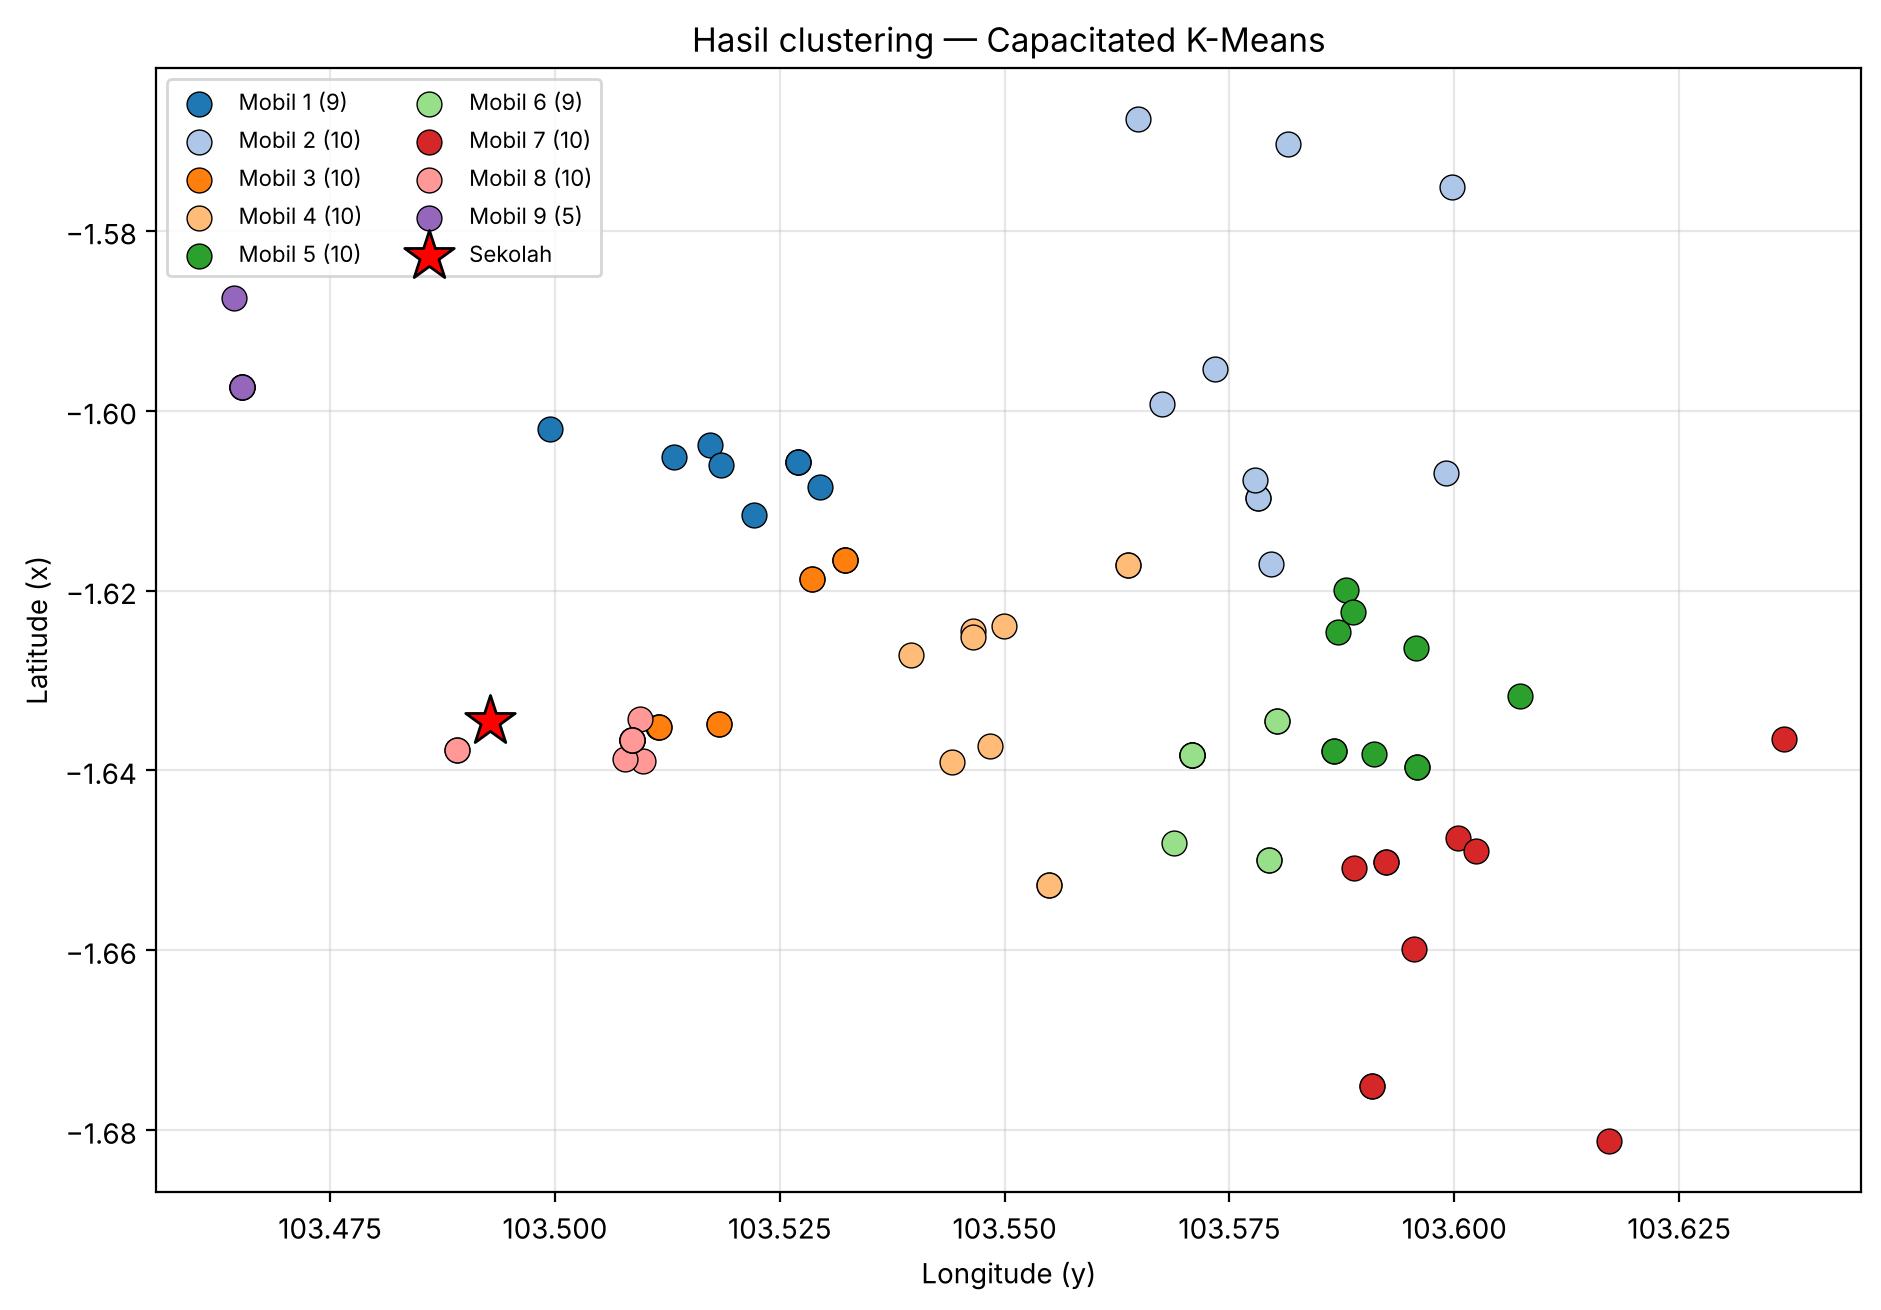

In [11]:
lat_s, lon_s = sekolah
fig, ax = plt.subplots(figsize=(11, 8))
cmap = plt.get_cmap("tab20")
for i, (kend, g) in enumerate(hasil.detail.groupby("kendaraan")):
    ax.scatter(g.lon, g.lat, s=80, color=cmap(i % 20), edgecolor="k", lw=.5, label=f"Mobil {kend} ({len(g)})", zorder=3)
ax.scatter([lon_s], [lat_s], marker="*", s=350, c="red", edgecolor="k", label="Sekolah", zorder=5)
ax.set_xlabel("Longitude (y)"); ax.set_ylabel("Latitude (x)"); ax.set_aspect("equal"); ax.grid(alpha=.3)
ax.legend(ncol=2, fontsize=8); ax.set_title(f"Hasil clustering — {hasil.metode}")
plt.show()

### (Opsional) Peta interaktif
Membutuhkan `plotly` dan koneksi internet.

In [12]:
try:
    import plotly.express as px
    d = hasil.detail.assign(Kendaraan="Mobil " + hasil.detail.kendaraan.astype(str))
    px.scatter_map(d, lat="lat", lon="lon", color="Kendaraan", hover_name="alamat",
                   zoom=11.5, height=600, map_style="open-street-map").show()
except Exception as e:
    print("Peta interaktif dilewati:", e)

## 8. Ekspor hasil

In [13]:
with open("hasil_clustering_antar_jemput.xlsx", "wb") as f:
    f.write(cc.ke_excel_bytes(hasil))
hasil.detail.to_csv("hasil_clustering_detail.csv", index=False, encoding="utf-8-sig")
hasil.ringkasan.to_csv("hasil_clustering_ringkasan.csv", index=False, encoding="utf-8-sig")
print("Tersimpan: hasil_clustering_antar_jemput.xlsx, hasil_clustering_detail.csv, hasil_clustering_ringkasan.csv")

Tersimpan: hasil_clustering_antar_jemput.xlsx, hasil_clustering_detail.csv, hasil_clustering_ringkasan.csv
